# Heuristic Optimisation Techniques – Assignment 2
## Experimental Evaluation

This notebook contains the experimental evaluation for Assignment 2.
It analyses solution quality, runtime behaviour, and statistical differences
between algorithms on the SCF-PDP test instances.

All experiments were run using the batch evaluation runner.


In [1]:
from pathlib import Path
import importlib
import pandas as pd
import matplotlib.pyplot as plt


In [ ]:
# ===== USER SETTINGS =====

# which evaluation script
EVAL_MODULE_NAME = "eval_fairness"

# folder containing solution files
# examples:
# "eval/jain"
# "eval/gini"
# "eval/maxmin"
EVAL_FOLDER = Path("outputs/2_fairness/LNS/100")

# optional: where to write CSV output
OUTPUT_CSV = Path("outputs/LNS/plots/results_q2_fairness_100.csv")


In [3]:
eval_module = importlib.import_module(EVAL_MODULE_NAME)

evaluate_folder = eval_module.evaluate_folder


In [4]:
eval_module = importlib.import_module(EVAL_MODULE_NAME)

evaluate_folder = eval_module.evaluate_folder


In [5]:
results = evaluate_folder(EVAL_FOLDER)

if not results:
    raise RuntimeError(f"No solution files found in {EVAL_FOLDER}")

df = pd.DataFrame(results)
df


,instance,total_cost,fairness,time_ms,drivers,stops
0,instance31_nreq100_nveh2_gamma86,4698.53,0.801847,45.8830,2,172
1,instance32_nreq100_nveh2_gamma89,4880.13,0.502164,48.3925,2,178
2,instance33_nreq100_nveh2_gamma92,4534.93,0.822652,53.7981,2,184
3,instance34_nreq100_nveh2_gamma87,4410.66,0.860642,30.9726,2,174
4,instance35_nreq100_nveh2_gamma89,4553.23,0.501989,47.9429,2,178
5,instance36_nreq100_nveh2_gamma90,4375.53,0.597579,69.2394,2,180
6,instance37_nreq100_nveh2_gamma89,5106.77,0.774373,29.4473,2,178
7,instance38_nreq100_nveh2_gamma88,4689.94,0.894099,24.0144,2,176
8,instance39_nreq100_nveh2_gamma92,4874.94,0.595591,37.9720,2,184
9,instance40_nreq100_nveh2_gamma86,4469.88,0.550244,25.5113,2,172


In [6]:
df.to_csv(OUTPUT_CSV, index=False)
print(f"Saved results to {OUTPUT_CSV}")


Saved results to results_q2_fairness_100.csv


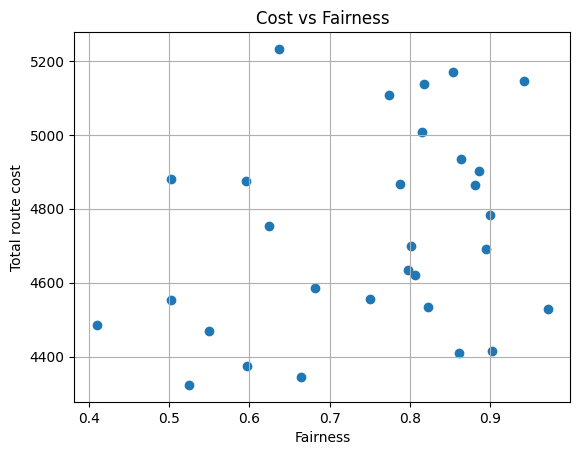

In [16]:
plt.figure()
plt.scatter(df["fairness"], df["total_cost"])
plt.xlabel("Fairness")
plt.ylabel("Total route cost")
plt.title("Cost vs Fairness")
plt.grid(True)
plt.show()


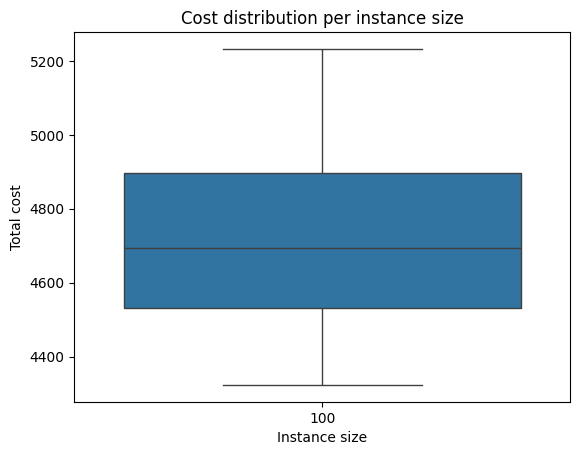

In [13]:
import seaborn as sns  # allowed in notebooks

df["size"] = df["instance"].str.extract(r"nreq(\d+)").astype(int)

plt.figure()
sns.boxplot(data=df, x="size", y="total_cost")
plt.xlabel("Instance size")
plt.ylabel("Total cost")
plt.title("Cost distribution per instance size")
plt.show()


In [ ]:
import numpy as np

def ecdf(data):
    x = np.sort(data)
    y = np.arange(1, len(x) + 1) / len(x)
    return x, y

plt.figure()

x, y = ecdf(df["total_cost"])
plt.step(x, y, where="post")

plt.xlabel("Total route cost")
plt.ylabel("Fraction of instances")
plt.title("ECDF of total route cost")
plt.grid(True)
plt.show()


NameError: name 'results_by_fairness' is not defined

In [14]:
summary = {
    "instances": len(df),
    "avg_cost": df["total_cost"].mean(),
    "avg_fairness": df["fairness"].mean(),
    "avg_stops": df["stops"].mean(),
    "avg_time_ms": df["time_ms"].mean(),
}

for k, v in summary.items():
    print(f"{k}: {v:.3f}" if isinstance(v, float) else f"{k}: {v}")


instances: 30
avg_cost: 4729.599
avg_fairness: 0.747
avg_stops: 178.467
avg_time_ms: 42.241


In [15]:
df["size"] = df["instance"].str.extract(r"nreq(\d+)").astype(int)

grouped = df.groupby("size").agg(
    avg_cost=("total_cost", "mean"),
    avg_fairness=("fairness", "mean"),
    avg_stops=("stops", "mean"),
)

grouped


,avg_cost,avg_fairness,avg_stops
size,,,
100,4729.599,0.747402,178.466667
